In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

users=pd.read_csv("../data/users.csv")
marketing = pd.read_csv("../data/marketing_spend.csv")

In [5]:
marketing.head()

,month,channel,spend_eur
0,2025-01-01,Meta Ads,3750.0
1,2025-01-01,Google Ads,3000.0
2,2025-01-01,TikTok Ads,0.0
3,2025-01-01,Influencers,0.0
4,2025-02-01,Meta Ads,3270.0


In [6]:
marketing.info()

<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   month      71 non-null     str    
 1   channel    71 non-null     str    
 2   spend_eur  71 non-null     float64
dtypes: float64(1), str(2)
memory usage: 1.8 KB


In [7]:
marketing.describe()

,spend_eur
count,71.000000
mean,3236.056338
std,2949.641372
min,0.000000
25%,0.000000
50%,3040.000000
75%,3800.000000
max,10820.000000


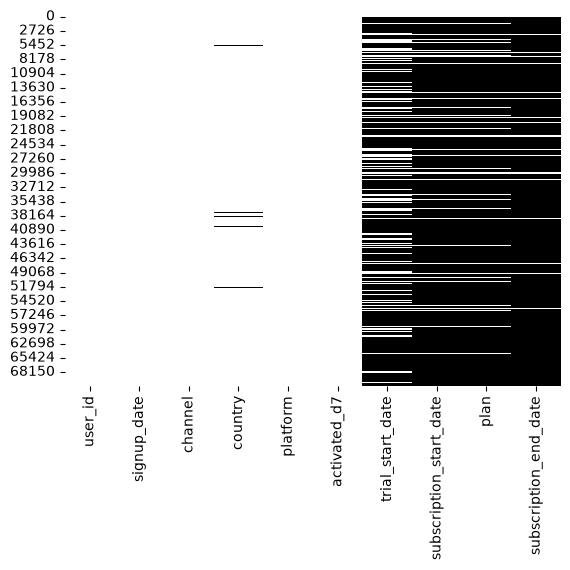

In [8]:
sns.heatmap(users.isna(), cbar=False, cmap='binary')
plt.show()

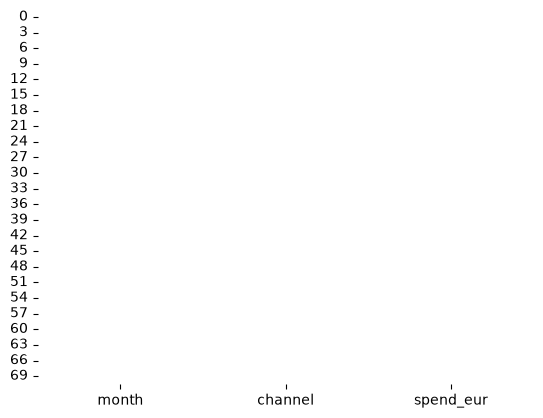

In [9]:
sns.heatmap(marketing.isna(), cbar=False, cmap='binary')
plt.show()

In [10]:
users.columns

Index(['user_id', 'signup_date', 'channel', 'country', 'platform',
       'activated_d7', 'trial_start_date', 'subscription_start_date', 'plan',
       'subscription_end_date'],
      dtype='str')

In [11]:
users.head()

,user_id,signup_date,channel,country,platform,activated_d7,trial_start_date,subscription_start_date,plan,subscription_end_date
0,U101247,2025-01-20,Organic,FR,iOS,0,NaN,NaN,NaN,NaN
1,U119636,2025-08-19,TikTok Ads,FR,Android,1,2025-08-20,NaN,NaN,NaN
2,U105849,2025-03-16,Organic,BE,Android,1,NaN,NaN,NaN,NaN
3,U147354,2026-02-11,TikTok Ads,FR,Android,1,2026-02-13,NaN,NaN,NaN
4,U118277,2025-08-06,Organic,FR,iOS,1,NaN,NaN,NaN,NaN


In [14]:
users.isna().sum()

user_id                        0
signup_date                    0
channel                        0
country                     1510
platform                       0
activated_d7                   0
trial_start_date           51412
subscription_start_date    63695
plan                       63695
subscription_end_date      68218
dtype: int64

In [18]:
users["subscription_start_date"].value_counts()

subscription_start_date
2026-06-10    39
2026-03-02    37
2026-02-28    33
2026-03-07    33
2026-02-23    32
              ..
2025-06-01     2
2025-06-07     2
2025-08-29     1
2025-03-07     1
2025-01-08     1
Name: count, Length: 539, dtype: int64

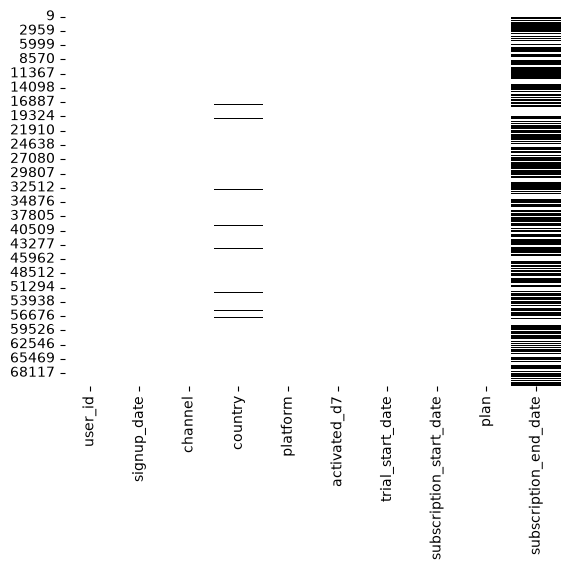

In [23]:
df = users[
    users["subscription_start_date"].notna()
].copy()
sns.heatmap(df.isna(), cbar=False, cmap='binary')
plt.show()

In [28]:
users["channel"].value_counts()

channel
TikTok Ads      17557
Meta Ads        16619
Organic         10166
Google Ads       8370
Influencers      7760
tiktok           3055
Referral         2947
meta_ads         1481
Facebook Ads     1436
google_ads       1415
internal           45
Name: count, dtype: int64

In [ ]:
mapping = {
    "facebook ads": "Facebook",
    "Facebook Ads": "Facebook",
    "facebook": "Facebook",
    "google ads": "Google",
    "Google Ads": "Google",
}

df["channel"] = df["channel"].str.strip().replace(mapping)